In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from statsmodels.tsa.seasonal import seasonal_decompose

In [4]:
df = pd.read_csv(r"C:\Users\Gowri\Downloads\store_sales.csv", parse_dates=["date"])
df = df.sort_values(["store", "date"])
df['dayofweek'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

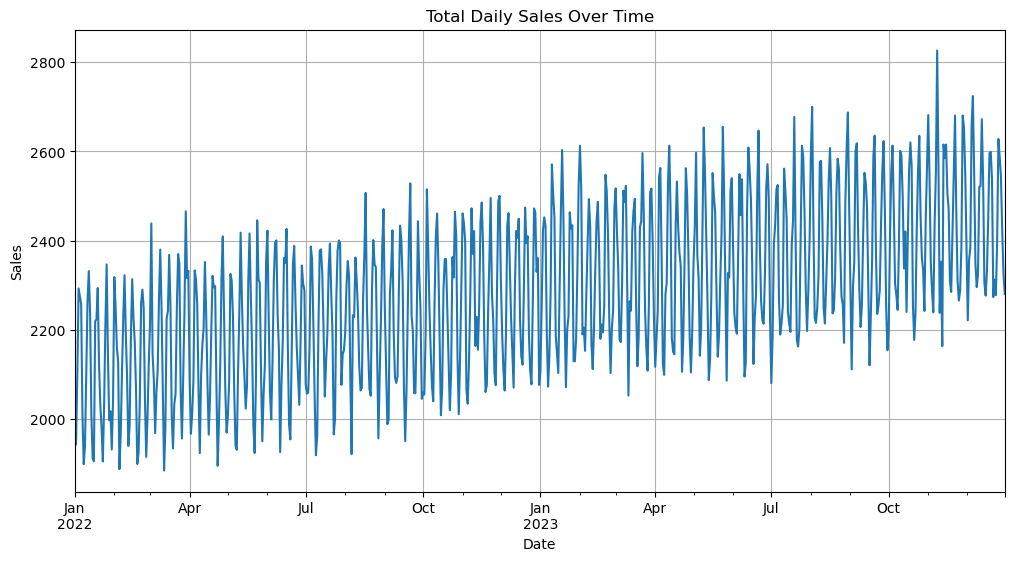

In [5]:
plt.figure(figsize=(12,6))
df.groupby('date')['sales'].sum().plot()
plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid()

ModuleNotFoundError: No module named 'prophet'

In [7]:
pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.1 MB 4.4 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/12.1 MB 4.3 MB/s eta 0:00:03
   ------ --------------------------------- 2.1/12.1 MB 3.3 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.1 MB 3.3 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.1 MB 3.3 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.1 MB 3.3 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/12.1 MB 1.6 MB/s eta 0:00:06
   ---------- ----------------------------- 3.1/12.1 MB 1.9 MB/s eta 0:00:05
   ---------- ----------------------------- 3.1/12.1 MB 1.9 MB/s eta 0:00:05
   ------------- -------------------------- 4.2/12.1 MB 1.8 MB/s eta 0:00:05
   ------------- -------------------------- 4.2/12.1 MB 1.8 MB/s eta 0:00:05
   ------------- -------------------------- 4.2/12.1 MB 1.8 MB/s eta 0:00:05
   ---

In [10]:
df = pd.read_csv(r"C:\Users\Gowri\Downloads\store_sales.csv", parse_dates=["date"])
df = df.sort_values(["store", "date"])
df['dayofweek'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

In [14]:
from prophet import Prophet

# Select store 1
store1 = df[df["store"] == 1].copy()

# Prepare data for Prophet
store_data = store1[["date", "sales"]].copy()
store_data.columns = ["ds", "y"]

store_data["ds"] = pd.to_datetime(store_data["ds"])

# Train the model
model = Prophet()
model.fit(store_data)

09:05:56 - cmdstanpy - INFO - Chain [1] start processing
09:06:02 - cmdstanpy - INFO - Chain [1] done processing


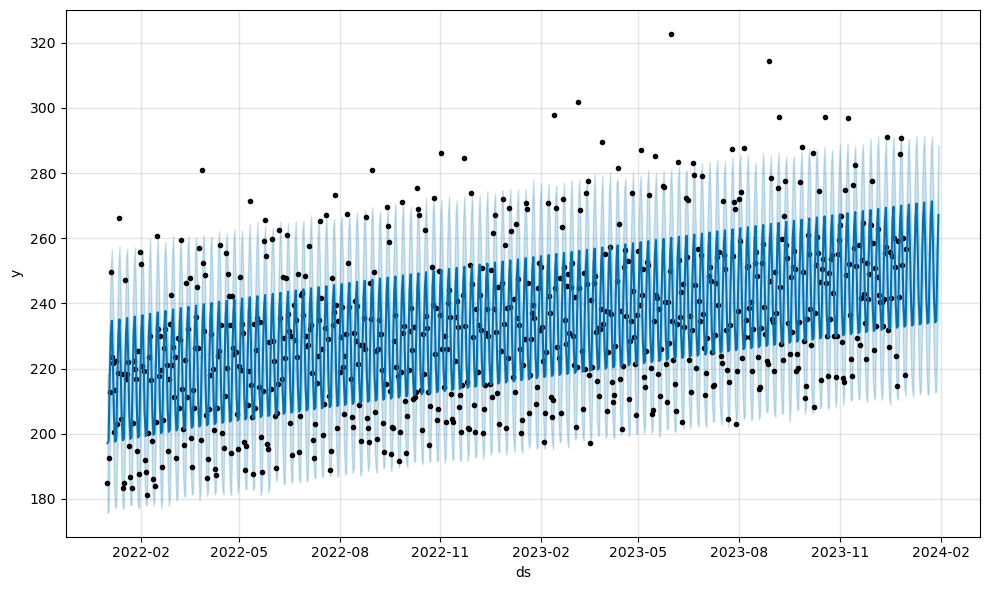

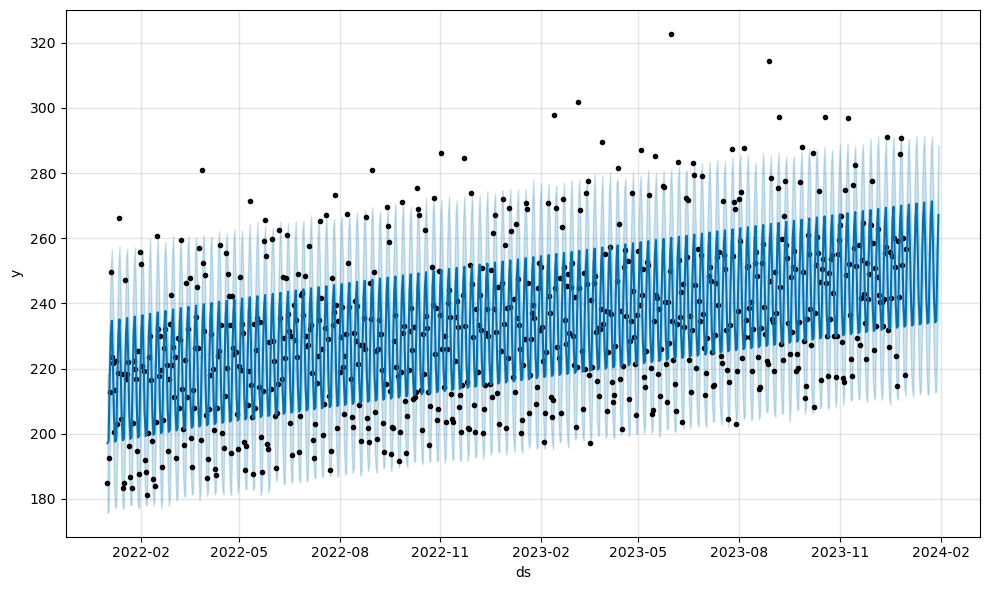

In [15]:
future = model.make_future_dataframe(periods=30)
forecast = model.predict(future)

model.plot(forecast)

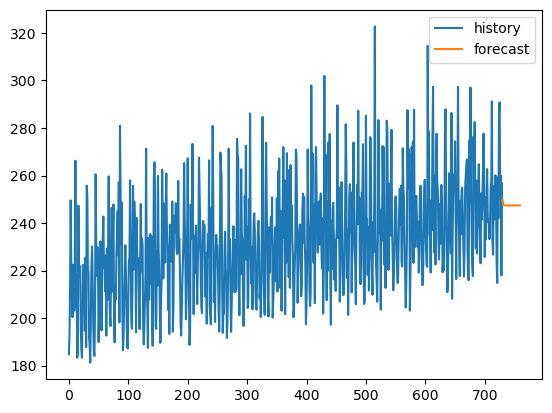

In [16]:
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(store1['sales'], order=(1,1,1))
model_fit = model_arima.fit()
forecast = model_fit.forecast(steps=30)

plt.plot(store1['sales'], label='history')
plt.plot(forecast, label='forecast')
plt.legend()
plt.show()